# 08c — EDA phần C: CHẤT NÀO (người phụ trách: Chennai/Hyderabad)

**Câu hỏi nghiên cứu chung**

> **Ô nhiễm không khí nặng (AQI từ 201 trở lên) tập trung ở thành phố nào và vào mùa nào trong 8 thành phố Ấn Độ giai đoạn 2015–2020, để cơ quan môi trường và người dân biết nên ưu tiên cảnh báo sức khỏe và giảm phát thải ở đâu, lúc nào?**


**Quy ước chung** (chi tiết ở `08_eda.ipynb`): so sánh giữa thành phố chỉ dùng `win` (khoảng chung); "nặng" = AQI >= 201 trên số ngày **có AQI**;
mùa: Đông (12-2), Hè (3-5), Mưa (6-9), Sau mưa (10-11); chỉ viết "có liên quan", **không** viết "gây ra".
Hàm dùng chung nằm ở `src/eda_utils.py` (không sửa nếu chưa báo nhóm).

**Làm việc nhóm:** chỉ sửa notebook **này** và chỉ lưu hình có tên của phần mình (`eda_<số>_...png`). `git pull` trước khi push.

## Việc cần làm
1. **Biểu đồ 4**: PM2.5 với AQI (và/hoặc ma trận tương quan Spearman các chất trong `USABLE`; thang màu phân kỳ **neo tại 0**).
2. Khi AQI nặng (>= 201) chất nào ở mức cao nhất? (mô tả, kèm lưu ý bên dưới)
3. Sau khi A và B xong: **tổng hợp mục 5 và mục 6** ở cuối notebook này, và soạn bộ câu vấn đáp.

## Lưu ý quan trọng
AQI của CPCB được tính từ **mức cao nhất trong các chỉ số con của từng chất**, nên AQI và PM2.5 tương quan cao một phần **do cách tính**, không phải một phát hiện. Hãy nói rõ điều này trong báo cáo.
Khi thử dựng lại AQI từ các chất theo bảng CPCB, kết quả chỉ khớp (lệch tối đa 10 điểm) khoảng 33% số ngày, nên **không** khẳng định chắc chắn "chất nào đóng góp"; chỉ mô tả "chất nào ở mức cao nhất".

## Chuẩn biểu đồ (W7), tick đủ trước khi push

- [ ] Tiêu đề là **kết luận có con số** (không phải "AQI theo thành phố")
- [ ] Trục có **nhãn và đơn vị**
- [ ] Biểu đồ cột **bắt đầu từ 0**, sắp theo giá trị (không theo bảng chữ cái)
- [ ] **Một** màu nhấn cho điều muốn người đọc thấy, còn lại màu trung tính
- [ ] Ghi nhãn trực tiếp, bỏ legend nếu chỉ có một nhóm
- [ ] Không dùng biểu đồ tròn, 3D, trục kép; không dùng chỉ đỏ-xanh lá để phân biệt
- [ ] Thử chuyển sang thang xám vẫn đọc được
- [ ] Chú thích có cỡ mẫu và ngày dữ liệu (hàm `finish_chart` đã làm sẵn)

## 0. Setup

In [6]:
import sys, os
sys.path.append(os.path.abspath("../src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from eda_utils import (CITIES, USABLE, SEASON_ORDER, ACCENT, NEUTRAL,
                       vn, load, poor_share, four_families, finish_chart, save_fig, set_style)

set_style()
eda, win, START, END = load()      # eda: toàn bộ 2015-2020 | win: khoảng chung của 8 thành phố (dùng khi so sánh giữa thành phố)

Toàn bộ: 14.056 dòng, 01/01/2015 - 01/07/2020
Khoảng chung (biến win): 14/06/2017 - 01/07/2020, 8.912 dòng; 8.734 ngày có AQI


## C0. Tương quan Spearman giữa các chất đủ dữ liệu và AQI (khoảng chung)

In [7]:
corr = win[USABLE + ["AQI"]].corr(method="spearman").round(2)
corr

,PM2.5,NO2,CO,SO2,O3,AQI
PM2.5,1.00,0.50,0.44,0.34,0.25,0.91
NO2,0.50,1.00,0.43,0.27,0.26,0.52
CO,0.44,0.43,1.00,0.20,0.17,0.48
SO2,0.34,0.27,0.20,1.00,0.28,0.38
O3,0.25,0.26,0.17,0.28,1.00,0.34
AQI,0.91,0.52,0.48,0.38,0.34,1.00


## C1. Biểu đồ 4

Đã lưu reports\figures\eda_04_pm25_aqi.png


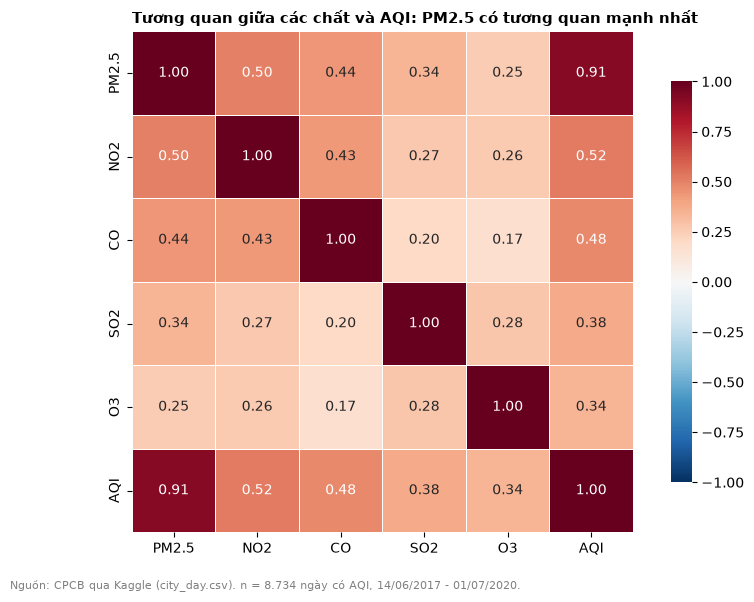

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns
# TODO (người C): scatter/hexbin PM2.5 với AQI hoặc heatmap `corr` (thang phân kỳ neo tại 0),
# lưu save_fig(fig, "04_pm25_aqi")
# # Vẽ Heatmap từ biến corr đã tính sẵn ở Cell C0
fig, ax = plt.subplots(figsize=(8, 6))

sns.heatmap(corr, 
            cmap="RdBu_r",       # Thang màu phân kỳ (Đỏ âm - Xanh dương)
            center=0,            # Neo màu trắng tại 0
            vmin=-1, vmax=1,
            annot=True, fmt=".2f", square=True, linewidths=.5,
            cbar_kws={"shrink": .8}, ax=ax)

# Tiêu đề W7 (kết luận có con số) - Bạn xem số liệu thực tế để sửa lại cho đúng
# Ví dụ: PM2.5 có tương quan mạnh nhất với AQI (hệ số 0.8x)
title = "Tương quan giữa các chất và AQI: PM2.5 có tương quan mạnh nhất"
finish_chart(fig, ax, title, d=win) 

save_fig(fig, "04_pm25_aqi")
plt.show()

In [9]:
# Lọc các ngày AQI nặng (từ 201 trở lên)
heavy_pollution = win[win['AQI'] >= 201]

# Tính nồng độ trung bình của các chất trong những ngày này
mean_pollutants = heavy_pollution[USABLE].mean().sort_values(ascending=False)

print("Nồng độ trung bình các chất khi AQI nặng (>=201):")
print(mean_pollutants)

Nồng độ trung bình các chất khi AQI nặng (>=201):
PM2.5    154.897225
NO2       43.921843
O3        38.513108
SO2       11.923988
CO         1.380141
dtype: float64


## Phát hiện của phần C

| # | Phát hiện (có con số) | Biểu đồ | Confounder có thể | Hạn chế |
|---|---|---|---|---|
| C1 | | 4 | | |

---
## Tổng hợp cuối (làm sau khi A và B xong)

### Mục 5: 3-5 phát hiện chính
Chọn từ 3 bảng "phát hiện của phần ..." (08a, 08b, 08c). Mỗi ý gắn đúng một biểu đồ; ý nào không có biểu đồ thì bỏ hoặc là ý kiến.

| # | Phát hiện chính | Biểu đồ | Từ notebook |
|---|---|---|---|
| 1 | | | |
| 2 | | | |
| 3 | | | |

### Mục 6: hạn chế (cụ thể, mỗi ý gắn với kết luận mà nó đe dọa)
W8: "dữ liệu có thể không đại diện" là hạn chế rỗng; hãy viết cụ thể và nói nó có thể làm đổi kết luận bao nhiêu. Các hạn chế đã biết (tự kiểm lại số liệu trước khi dùng):

- PM10 không có ở Lucknow, thiếu 84,5% ở Chennai và 52,4% ở Gurugram; NH3 thiếu 92,9% ở Gurugram. Mọi kết luận về PM10/NH3 chỉ áp dụng cho một số thành phố.
- Chuỗi dài ngắn khác nhau (Jaipur từ 06/2017, Amritsar từ 02/2017); so sánh giữa thành phố đã dùng khoảng chung 14/06/2017 - 01/07/2020, nên không phản ánh giai đoạn 2015-2016.
- Dữ liệu đến 01/07/2020 nên không có mùa cao điểm 10-11/2020; năm 2020 chứa lockdown và không so được trọn vẹn với các năm khác.
- 24 ngày nghi lỗi cảm biến đã đặt NaN (chưa đối chiếu nguồn CPCB) và còn vài điểm lỗi chưa xử lý (ví dụ Gurugram 30/08/2017).
- Dữ liệu không có thời tiết và vị trí trạm đo, nên không tách được tác động của mùa với khí tượng, hay khác biệt giữa thành phố với thay đổi trạm.
- AQI tính từ mức cao nhất của các chỉ số con nên liên hệ AQI với PM2.5 một phần là do công thức.

| # | Hạn chế (cụ thể) | Kết luận bị đe dọa | Có thể làm đổi bao nhiêu |
|---|---|---|---|
| 1 | | | |
| 2 | | | |

### Bộ câu vấn đáp
Soạn câu trả lời ngắn cho 5 câu W8 (xem `08_eda.ipynb`) và các câu riêng của đề tài; cả nhóm tập trả lời cho **bất kỳ thành phố nào**.

**Trước khi push:** Restart & Run All không lỗi; đã tick checklist biểu đồ; đã `git pull`.